In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

df = pd.read_csv("market_raw.csv")
df.head()

,order_id,order_date,product,category,quantity,unit_price,payment_method,city
0,ORD001,2026-08-01,Mechanical Keyboard,Electronics,2.0,450000.0,QRIS,Makassar
1,ORD002,2026-08-01,Wireless Mouse,Electronics,3.0,150000.0,Transfer,Makassar
2,ORD003,2026-08-02,USB Hub,Accessories,4.0,85000.0,QRIS,Gowa
3,ORD004,2026-08-02,Mechanical Keyboard,electronics,1.0,450000.0,E-Wallet,Makassar
4,ORD005,2026-08-03,Laptop Stand,ACCESSORIES,2.0,175000.0,Transfer,Maros


In [4]:
print("Baris:", df.shape[0])
print("Kolom:", df.shape[1])
df.info()
df.describe(include="all")


Baris: 21
Kolom: 8
<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        21 non-null     str    
 1   order_date      21 non-null     str    
 2   product         21 non-null     str    
 3   category        21 non-null     str    
 4   quantity        20 non-null     float64
 5   unit_price      20 non-null     float64
 6   payment_method  21 non-null     str    
 7   city            21 non-null     str    
dtypes: float64(2), str(6)
memory usage: 2.5 KB


,order_id,order_date,product,category,quantity,unit_price,payment_method,city
count,21,21,21,21,20.000000,20.000000,21,21
unique,20,11,4,4,NaN,NaN,3,4
top,ORD019,2026-08-01,Wireless Mouse,Electronics,NaN,NaN,QRIS,Makassar
freq,2,2,6,10,NaN,NaN,10,10
mean,NaN,NaN,NaN,NaN,2.950000,209250.000000,NaN,NaN
std,NaN,NaN,NaN,NaN,1.356272,146361.799373,NaN,NaN
min,NaN,NaN,NaN,NaN,1.000000,85000.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,2.000000,85000.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,3.000000,150000.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,4.000000,243750.000000,NaN,NaN


In [5]:
df.isna().sum()
print("Duplikat:", df.duplicated().sum())
df = df.drop_duplicates()
print("Ukuran setelah menghapus duplikat:", df.shape)


Duplikat: 1
Ukuran setelah menghapus duplikat: (20, 8)


In [10]:
text_columns = ["product", "category", "payment_method", "city"]
for col in text_columns:
    df[col] = df[col].str.strip().str.title()


df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df[df["order_date"].isna()]  # periksa tanggal tidak valid
df = df.dropna(subset=["order_date"])


In [11]:
df = df.dropna(subset=["quantity"])

df["unit_price"] = df.groupby("product")["unit_price"].transform(
    lambda x: x.fillna(x.median())
)

df.isna().sum()


order_id          0
order_date        0
product           0
category          0
quantity          0
unit_price        0
payment_method    0
city              0
dtype: int64

In [12]:
df["revenue"] = df["quantity"] * df["unit_price"]

print("Baris bersih:", len(df))
print("Duplikat tersisa:", df.duplicated().sum())
print("Missing values tersisa:", df.isna().sum().sum())

df.to_csv("digimart_clean.csv", index=False)


Baris bersih: 18
Duplikat tersisa: 0
Missing values tersisa: 0


Exploratory Data Analysis

In [13]:
total_revenue = df["revenue"].sum()
total_units = df["quantity"].sum()
transaction_count = df["order_id"].nunique()
average_revenue_per_row = df["revenue"].mean()

print(f"Total revenue: Rp{total_revenue:,.0f}")
print(f"Units sold: {total_units}")
print(f"Unique transactions: {transaction_count}")
print(f"Average revenue per row: Rp{average_revenue_per_row:,.0f}")


Total revenue: Rp9,605,000
Units sold: 54.0
Unique transactions: 18
Average revenue per row: Rp533,611


In [14]:
category_revenue = (
    df.groupby("category")["revenue"]
      .sum()
      .sort_values(ascending=False)
)
city_revenue = (
    df.groupby("city")["revenue"]
      .sum()
      .sort_values(ascending=False)
)
display(category_revenue)
display(city_revenue)


category
Electronics    6150000.0
Accessories    3455000.0
Name: revenue, dtype: float64

city
Makassar    5150000.0
Gowa        3325000.0
Maros       1130000.0
Name: revenue, dtype: float64

In [15]:
daily_sales = (
    df.groupby("order_date")["revenue"]
      .sum()
      .reset_index()
)
display(daily_sales.head())


,order_date,revenue
0,2026-08-01,1350000.0
1,2026-08-02,790000.0
2,2026-08-03,1100000.0
3,2026-08-04,525000.0
4,2026-08-05,1410000.0


 Visualisasi

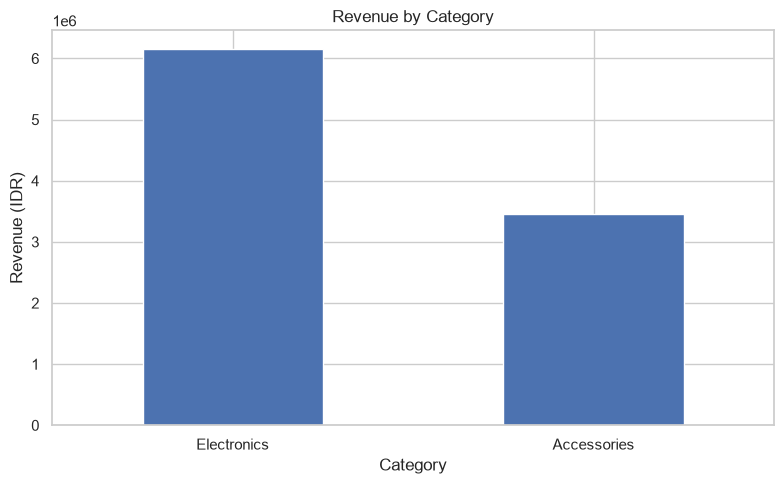

In [16]:
category_revenue.plot(kind="bar", figsize=(8, 5), title="Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue (IDR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


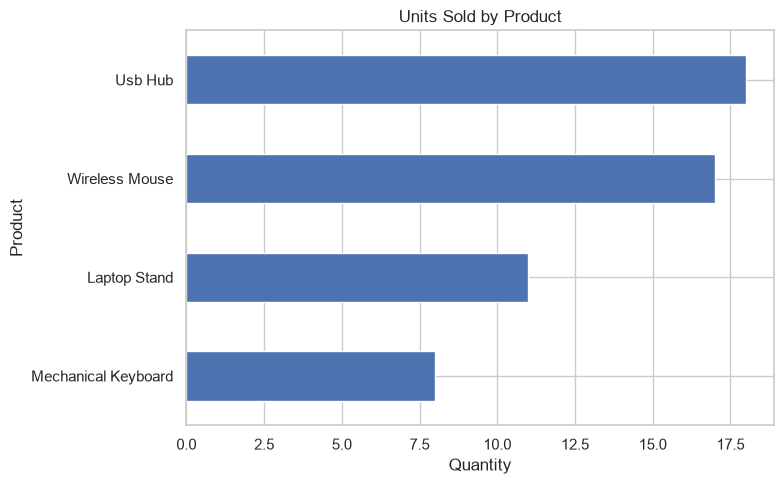

In [25]:
product_units = df.groupby("product")["quantity"].sum()

product_units.sort_values().plot(kind="barh", figsize=(8, 5),
                                     title="Units Sold by Product")
plt.xlabel("Quantity")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


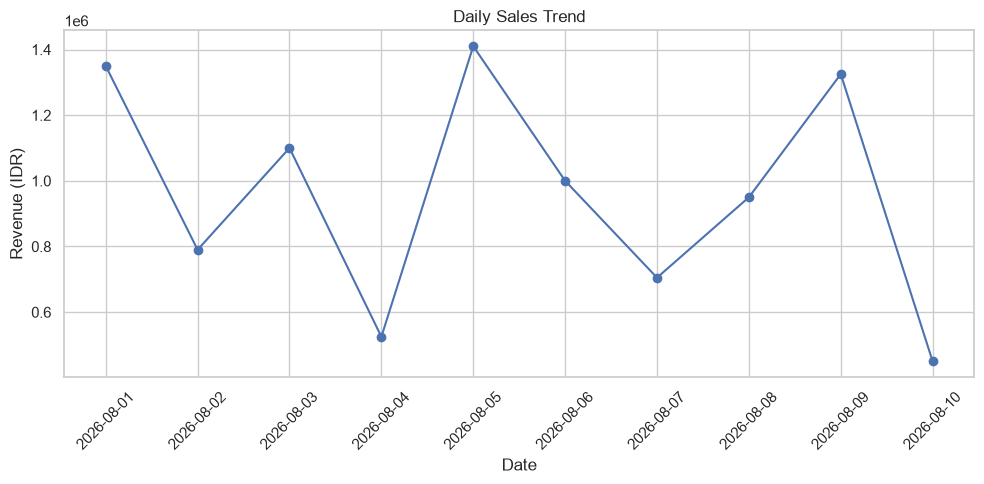

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(daily_sales["order_date"], daily_sales["revenue"], marker="o")
plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Revenue (IDR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [30]:
%pip install --upgrade nbformat ipython
import plotly.express as px
from IPython.display import display

print("DIGIMART SALES DASHBOARD")
print(f"Total Revenue: Rp{df['revenue'].sum():,.0f}")
print(f"Units Sold: {df['quantity'].sum():,}")
print(f"Transactions: {df['order_id'].nunique():,}")

category_data = df.groupby("category", as_index=False)["revenue"].sum()
fig = px.bar(category_data, x="category", y="revenue",
             title="Revenue by Category", text_auto=".2s")
fig.show()

daily_data = df.groupby("order_date", as_index=False)["revenue"].sum()
fig = px.line(daily_data, x="order_date", y="revenue",
              markers=True, title="Daily Revenue Trend")
fig.show()

product_data = df.groupby("product", as_index=False)["revenue"].sum()
fig = px.bar(product_data, x="revenue", y="product",
             orientation="h", title="Revenue by Product")
fig.show()


Note: you may need to restart the kernel to use updated packages.
DIGIMART SALES DASHBOARD
Total Revenue: Rp9,605,000
Units Sold: 54.0
Transactions: 18


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed